# LE5 - Zentrale Aktoren & Aktor-Gruppen finden

This notebook analyzes network centrality measures to identify the most important actors in football networks:

1. **Degree Centrality**: Players/teams with most connections
2. **Betweenness Centrality**: Actors that bridge different parts of the network
3. **Closeness Centrality**: Actors with shortest paths to all others
4. **Eigenvector Centrality / PageRank**: Actors connected to other important actors
5. **Actor Groups**: k-cores, k-shells, and bridging nodes

We will analyze both pass networks (players) and match networks (teams).

In [1]:
# Import required libraries
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns


# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [2]:
from src.config import (
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR,
)

In [3]:
# General settings
warnings.filterwarnings('ignore')

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

In [4]:
# Load networks
print("=== Loading Networks ===\n")

# Pass Network (directed, weighted)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass_dir = nx.read_gexf(pass_network_path)
print(f"Pass Network (Germany): {G_pass_dir.number_of_nodes()} nodes, {G_pass_dir.number_of_edges()} edges")

# Convert to undirected for some centrality measures
G_pass = G_pass_dir.to_undirected()

# Match Network (directed)
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
G_match_dir = nx.read_gexf(match_network_path)
print(f"Match Network (World Cup): {G_match_dir.number_of_nodes()} nodes, {G_match_dir.number_of_edges()} edges")

# Convert to undirected
G_match = G_match_dir.to_undirected()

# Unified Pass Network
unified_pass_path = PASS_NETWORKS_DIR / 'pass_network_unified.gexf'
if unified_pass_path.exists():
    G_unified_dir = nx.read_gexf(unified_pass_path)
    G_unified = G_unified_dir.to_undirected()
    print(f"Unified Pass Network: {G_unified.number_of_nodes()} nodes, {G_unified.number_of_edges()} edges")
else:
    G_unified = None
    print("Unified pass network not found")

print("\nNetworks loaded successfully!")

=== Loading Networks ===

Pass Network (Germany): 473 nodes, 9341 edges
Match Network (World Cup): 32 nodes, 126 edges
Unified Pass Network: 3029 nodes, 33273 edges

Networks loaded successfully!


## 1. Degree Centrality

**Degree Centrality** measures how many connections a node has. In undirected networks, it's simply the number of edges connected to a node. In directed networks, we distinguish:
- **In-degree**: number of incoming edges
- **Out-degree**: number of outgoing edges

For **weighted networks**, we use **strength** (weighted degree) instead:
- Sum of edge weights for all adjacent edges

### Theoretical Background

For an undirected network with adjacency matrix $A$:
$$C_D(i) = \sum_{j} A_{ij}$$

**Normalized Degree Centrality**:
$$C_D^{norm}(i) = \frac{C_D(i)}{n-1}$$

where $n$ is the number of nodes. This normalizes to $[0,1]$.

### Interpretation
- High degree centrality → node is well-connected (popular, influential)
- In pass networks: players who pass/receive frequently
- In match networks: teams that play against many different opponents

In [5]:
### 1.1 Degree Centrality - Pass Network (Undirected)

# Calculate degree centrality (normalized and unnormalized)
degree_cent = nx.degree_centrality(G_pass)
degree_raw = dict(G_pass.degree())

# Create DataFrame for analysis
df_degree_pass = pd.DataFrame({
    'Player': list(degree_cent.keys()),
    'Degree': [degree_raw[p] for p in degree_cent.keys()],
    'Degree_Centrality': list(degree_cent.values()),
})
df_degree_pass = df_degree_pass.sort_values('Degree', ascending=False)

print("=== Top 15 Players by Degree (Pass Network - Germany) ===\n")
print(df_degree_pass.head(15).to_string(index=False))
print(f"\nTotal players: {len(df_degree_pass)}")
print(f"Max degree: {df_degree_pass['Degree'].max()}")
print(f"Mean degree: {df_degree_pass['Degree'].mean():.2f}")
print(f"Median degree: {df_degree_pass['Degree'].median():.1f}")

=== Top 15 Players by Degree (Pass Network - Germany) ===

Player  Degree  Degree_Centrality
 15085      50           0.105932
 16094      45           0.095339
284469      45           0.095339
149389      44           0.093220
 14731      41           0.086864
 15771      39           0.082627
105619      38           0.080508
302600      36           0.076271
241966      35           0.074153
 14687      34           0.072034
 15191      34           0.072034
 14749      34           0.072034
 16110      33           0.069915
 15129      33           0.069915
 15253      33           0.069915

Total players: 473
Max degree: 50
Mean degree: 22.22
Median degree: 24.0


In [6]:
### 1.2 Degree Centrality with Weights (Strength)

# For weighted networks, we use "strength" (sum of edge weights)
# Get weighted degree (strength)
def calculate_strength(G):
    """Calculate weighted degree (strength) for each node"""
    strength = {}
    for node in G.nodes():
        s = 0
        for neighbor in G.neighbors(node):
            if 'weight' in G[node][neighbor]:
                s += float(G[node][neighbor]['weight'])
            else:
                s += 1
        strength[node] = s
    return strength

strength_pass = calculate_strength(G_pass)

df_strength_pass = pd.DataFrame({
    'Player': list(strength_pass.keys()),
    'Strength': list(strength_pass.values()),
    'Degree': [degree_raw[p] for p in strength_pass.keys()],
})
df_strength_pass = df_strength_pass.sort_values('Strength', ascending=False)

print("=== Top 15 Players by Strength (Weighted Degree) ===\n")
print(df_strength_pass.head(15).to_string(index=False))

# Compare degree vs strength
print(f"\nMean strength: {df_strength_pass['Strength'].mean():.2f}")
print(f"Max strength: {df_strength_pass['Strength'].max():.0f}")
print(f"Correlation degree-strength: {df_strength_pass['Degree'].corr(df_strength_pass['Strength']):.3f}")

=== Top 15 Players by Strength (Weighted Degree) ===

Player  Strength  Degree
 14842    1290.0      28
 14687    1259.0      34
 14778    1240.0      32
340646    1098.0      27
 14991    1049.0      25
134383     957.0      28
 15806     918.0      26
    77     888.0      25
  8309     867.0      23
  3416     829.0      30
228768     829.0      26
 14718     793.0      28
 14838     792.0      25
 20932     784.0      21
 14716     773.0      26

Mean strength: 248.89
Max strength: 1290
Correlation degree-strength: 0.587


In [7]:
### 1.3 In-Degree and Out-Degree (Directed Pass Network)

# Use directed network
in_degree_cent = nx.in_degree_centrality(G_pass_dir)
out_degree_cent = nx.out_degree_centrality(G_pass_dir)

df_directed_degree = pd.DataFrame({
    'Player': list(in_degree_cent.keys()),
    'In_Degree_Cent': list(in_degree_cent.values()),
    'Out_Degree_Cent': list(out_degree_cent.values()),
    'In_Degree': [G_pass_dir.in_degree(p) for p in in_degree_cent.keys()],
    'Out_Degree': [G_pass_dir.out_degree(p) for p in in_degree_cent.keys()],
})

# Top receivers (in-degree)
print("=== Top 10 Players by In-Degree (Pass Receivers) ===\n")
df_in = df_directed_degree.sort_values('In_Degree', ascending=False)
print(df_in[['Player', 'In_Degree', 'In_Degree_Cent']].head(10).to_string(index=False))

# Top passers (out-degree)
print("\n=== Top 10 Players by Out-Degree (Pass Givers) ===\n")
df_out = df_directed_degree.sort_values('Out_Degree', ascending=False)
print(df_out[['Player', 'Out_Degree', 'Out_Degree_Cent']].head(10).to_string(index=False))

=== Top 10 Players by In-Degree (Pass Receivers) ===

Player  In_Degree  In_Degree_Cent
 15085         46        0.097458
 16094         44        0.093220
284469         42        0.088983
149389         40        0.084746
 14731         39        0.082627
105619         36        0.076271
 14749         31        0.065678
 16110         31        0.065678
356903         31        0.065678
 15771         31        0.065678

=== Top 10 Players by Out-Degree (Pass Givers) ===

Player  Out_Degree  Out_Degree_Cent
 15085          46         0.097458
284469          43         0.091102
149389          42         0.088983
105619          36         0.076271
 15771          35         0.074153
 16094          35         0.074153
 14731          33         0.069915
228980          32         0.067797
 15191          31         0.065678
 14687          31         0.065678


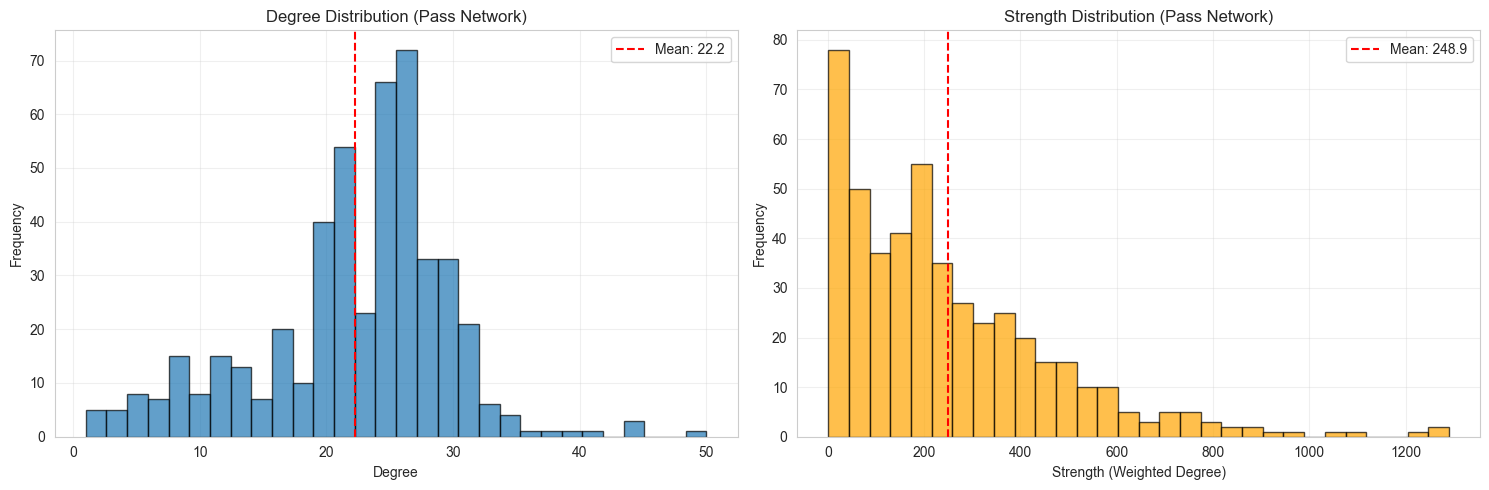

Figure saved: reports/figures/LE5/degree_distribution.png


In [8]:
### 1.4 Visualization - Degree Distribution

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Degree distribution
axes[0].hist(df_degree_pass['Degree'], bins=30, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Degree Distribution (Pass Network)')
axes[0].axvline(df_degree_pass['Degree'].mean(), color='red', linestyle='--', label=f'Mean: {df_degree_pass["Degree"].mean():.1f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Strength distribution
axes[1].hist(df_strength_pass['Strength'], bins=30, edgecolor='black', alpha=0.7, color='orange')
axes[1].set_xlabel('Strength (Weighted Degree)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Strength Distribution (Pass Network)')
axes[1].axvline(df_strength_pass['Strength'].mean(), color='red', linestyle='--', label=f'Mean: {df_strength_pass["Strength"].mean():.1f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'degree_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/degree_distribution.png")

## 2. Betweenness Centrality

**Betweenness Centrality** measures how often a node lies on the shortest paths between other nodes. Nodes with high betweenness act as bridges or brokers in the network.

### Theoretical Background

$$C_B(i) = \sum_{s \neq i \neq t} \frac{\sigma_{st}(i)}{\sigma_{st}}$$

where:
- $\sigma_{st}$ = total number of shortest paths from $s$ to $t$
- $\sigma_{st}(i)$ = number of those paths passing through node $i$

**Normalized Betweenness**:
$$C_B^{norm}(i) = \frac{2 \cdot C_B(i)}{(n-1)(n-2)}$$

### Interpretation
- High betweenness → node controls information flow, acts as bridge
- Removal of high-betweenness nodes can fragment the network
- In pass networks: players who connect different parts of the team
- In match networks: teams that bridge different competitive groups

In [9]:
### 2.1 Betweenness Centrality - Pass Network

# Calculate betweenness centrality (this can be computationally expensive)
print("Calculating betweenness centrality (this may take a moment)...")

# Get largest connected component
components = list(nx.connected_components(G_pass))
largest_cc = max(components, key=len)
G_pass_cc = G_pass.subgraph(largest_cc).copy()

print(f"Using largest connected component: {len(largest_cc)} / {G_pass.number_of_nodes()} nodes")

betweenness_cent = nx.betweenness_centrality(G_pass_cc, normalized=True)

df_betweenness = pd.DataFrame({
    'Player': list(betweenness_cent.keys()),
    'Betweenness_Centrality': list(betweenness_cent.values()),
})
df_betweenness = df_betweenness.sort_values('Betweenness_Centrality', ascending=False)

print("\n=== Top 15 Players by Betweenness Centrality ===\n")
print(df_betweenness.head(15).to_string(index=False))

print(f"\nMean betweenness: {df_betweenness['Betweenness_Centrality'].mean():.6f}")
print(f"Max betweenness: {df_betweenness['Betweenness_Centrality'].max():.6f}")
print(f"Players with zero betweenness: {(df_betweenness['Betweenness_Centrality'] == 0).sum()}")

Calculating betweenness centrality (this may take a moment)...
Using largest connected component: 473 / 473 nodes

=== Top 15 Players by Betweenness Centrality ===

Player  Betweenness_Centrality
336829                0.026213
302600                0.026010
 65075                0.023694
 14795                0.020566
 14749                0.018584
 15085                0.017746
 15191                0.016745
 14989                0.015695
228980                0.015544
241966                0.015389
 14689                0.015119
 21469                0.014476
 14988                0.014256
134392                0.013433
127685                0.013363

Mean betweenness: 0.003771
Max betweenness: 0.026213
Players with zero betweenness: 44


In [10]:
### 2.2 Comparison: Degree vs Betweenness

# Merge degree and betweenness data
df_comparison = df_degree_pass.merge(df_betweenness, on='Player', how='outer')
df_comparison = df_comparison.fillna(0)
df_comparison = df_comparison.sort_values('Betweenness_Centrality', ascending=False)

print("=== Players with Highest Betweenness (comparing with Degree) ===\n")
print(df_comparison[['Player', 'Degree', 'Degree_Centrality', 'Betweenness_Centrality']].head(15).to_string(index=False))

# Calculate correlation
corr = df_comparison['Degree_Centrality'].corr(df_comparison['Betweenness_Centrality'])
print(f"\nCorrelation Degree-Betweenness: {corr:.3f}")

# Find players with high betweenness but low degree (bridging nodes)
df_comparison['Degree_Rank'] = df_comparison['Degree'].rank(ascending=False)
df_comparison['Betweenness_Rank'] = df_comparison['Betweenness_Centrality'].rank(ascending=False)
df_comparison['Rank_Diff'] = df_comparison['Degree_Rank'] - df_comparison['Betweenness_Rank']

print("\n=== Bridging Nodes: High Betweenness, Relatively Low Degree ===")
bridging_candidates = df_comparison[
    (df_comparison['Betweenness_Rank'] <= 30) & 
    (df_comparison['Rank_Diff'] > 20)
].sort_values('Betweenness_Centrality', ascending=False)
print(bridging_candidates[['Player', 'Degree', 'Betweenness_Centrality', 'Degree_Rank', 'Betweenness_Rank']].head(10).to_string(index=False))

=== Players with Highest Betweenness (comparing with Degree) ===

Player  Degree  Degree_Centrality  Betweenness_Centrality
336829      33           0.069915                0.026213
302600      36           0.076271                0.026010
 65075      33           0.069915                0.023694
 14795      33           0.069915                0.020566
 14749      34           0.072034                0.018584
 15085      50           0.105932                0.017746
 15191      34           0.072034                0.016745
 14989      31           0.065678                0.015695
228980      32           0.067797                0.015544
241966      35           0.074153                0.015389
 14689      31           0.065678                0.015119
 21469      32           0.067797                0.014476
 14988      29           0.061441                0.014256
134392      30           0.063559                0.013433
127685      31           0.065678                0.013363

Corre

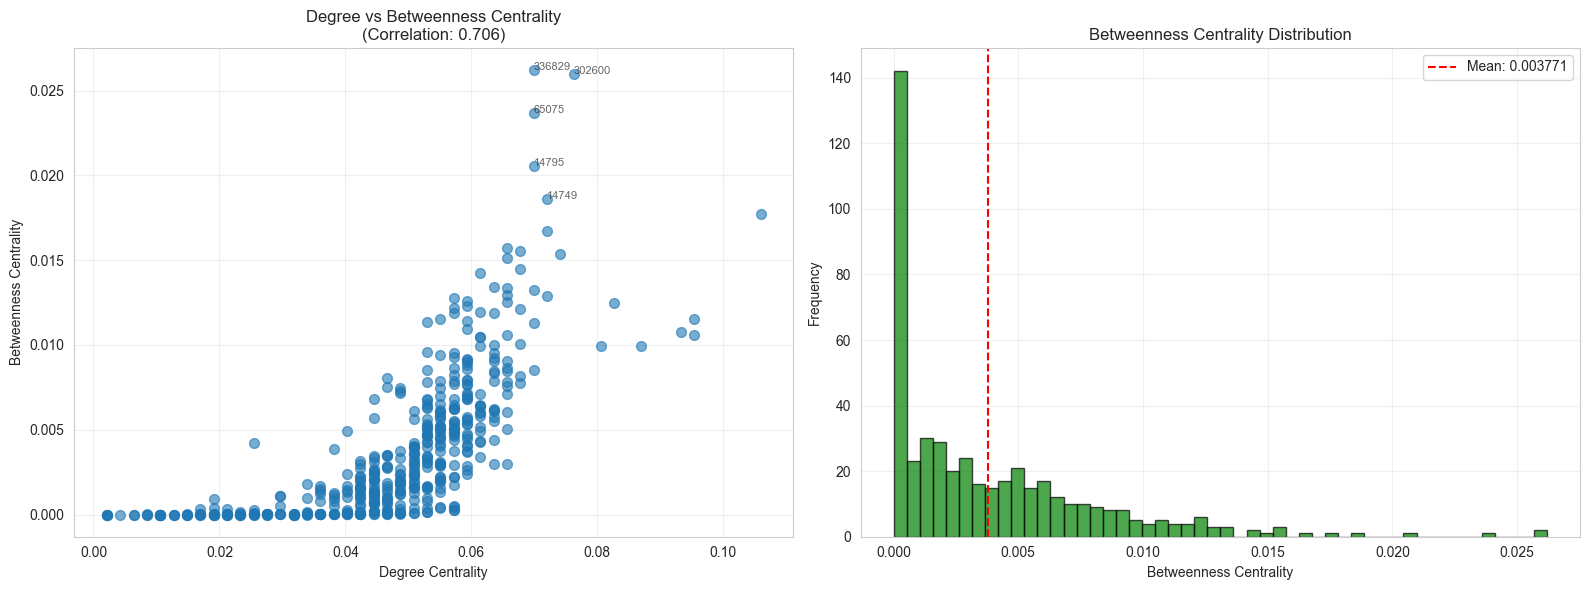

Figure saved: reports/figures/LE5/betweenness_analysis.png


In [11]:
### 2.3 Visualization - Degree vs Betweenness Scatter

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot
axes[0].scatter(df_comparison['Degree_Centrality'], 
                df_comparison['Betweenness_Centrality'],
                alpha=0.6, s=50)
axes[0].set_xlabel('Degree Centrality')
axes[0].set_ylabel('Betweenness Centrality')
axes[0].set_title(f'Degree vs Betweenness Centrality\n(Correlation: {corr:.3f})')
axes[0].grid(True, alpha=0.3)

# Annotate top players
top_n = 5
top_betweenness = df_comparison.nlargest(top_n, 'Betweenness_Centrality')
for _, row in top_betweenness.iterrows():
    axes[0].annotate(row['Player'][:15], 
                     (row['Degree_Centrality'], row['Betweenness_Centrality']),
                     fontsize=8, alpha=0.7)

# Betweenness distribution
axes[1].hist(df_betweenness['Betweenness_Centrality'], bins=50, edgecolor='black', alpha=0.7, color='green')
axes[1].set_xlabel('Betweenness Centrality')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Betweenness Centrality Distribution')
axes[1].axvline(df_betweenness['Betweenness_Centrality'].mean(), 
                color='red', linestyle='--', 
                label=f'Mean: {df_betweenness["Betweenness_Centrality"].mean():.6f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'betweenness_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/betweenness_analysis.png")

## 3. Closeness Centrality

**Closeness Centrality** measures how close a node is to all other nodes in the network. It's based on the average shortest path length to all other reachable nodes.

### Theoretical Background

$$C_C(i) = \frac{n-1}{\sum_{j \neq i} d(i,j)}$$

where $d(i,j)$ is the shortest path distance from $i$ to $j$.

**Normalized Closeness** is already in $[0,1]$ range.

### Interpretation
- High closeness → node can quickly reach all others
- In pass networks: players who are well-integrated in the team's passing structure
- Requires connected components (or disconnected: uses harmonic mean)
- Only meaningful in connected graphs or with adaptations for disconnected graphs

**Note**: NetworkX uses **harmonic centrality** for disconnected graphs, which uses the reciprocal of distances.

In [12]:
### 3.1 Closeness Centrality - Pass Network

# Calculate closeness on largest connected component
closeness_cent = nx.closeness_centrality(G_pass_cc)

df_closeness = pd.DataFrame({
    'Player': list(closeness_cent.keys()),
    'Closeness_Centrality': list(closeness_cent.values()),
})
df_closeness = df_closeness.sort_values('Closeness_Centrality', ascending=False)

print("=== Top 15 Players by Closeness Centrality ===\n")
print(df_closeness.head(15).to_string(index=False))

print(f"\nMean closeness: {df_closeness['Closeness_Centrality'].mean():.6f}")
print(f"Max closeness: {df_closeness['Closeness_Centrality'].max():.6f}")
print(f"Min closeness: {df_closeness['Closeness_Centrality'].min():.6f}")

=== Top 15 Players by Closeness Centrality ===

Player  Closeness_Centrality
 65075              0.433425
 14795              0.428312
302600              0.423698
 14749              0.418069
 15191              0.417699
134392              0.414035
 15085              0.410792
241966              0.407952
135561              0.406546
228980              0.406546
 15129              0.406196
327009              0.404803
 25861              0.404456
 21469              0.403419
 14778              0.402044

Mean closeness: 0.362201
Max closeness: 0.433425
Min closeness: 0.244306


## 4. Eigenvector Centrality and PageRank

**Eigenvector Centrality** measures the influence of a node based on the quality of its connections. A node has high eigenvector centrality if it's connected to other high-centrality nodes.

### Theoretical Background

Eigenvector centrality $\mathbf{x}$ satisfies:
$$\mathbf{x} = \lambda \mathbf{A} \mathbf{x}$$

where $\lambda$ is the largest eigenvalue of adjacency matrix $\mathbf{A}$.

**PageRank** is a variant that adds a damping factor $\alpha$ (typically 0.85):
$$PR(i) = \frac{1-\alpha}{n} + \alpha \sum_{j \to i} \frac{PR(j)}{deg^{out}(j)}$$

### Interpretation
- **Eigenvector**: being connected to important nodes makes you important
- **PageRank**: accounts for directed networks, includes random walk probability
- In pass networks: players connected to key players
- PageRank better for directed networks (pass direction matters)

In [13]:
### 4.1 Eigenvector Centrality - Undirected Pass Network

try:
    eigenvector_cent = nx.eigenvector_centrality(G_pass_cc, max_iter=500)
    
    df_eigenvector = pd.DataFrame({
        'Player': list(eigenvector_cent.keys()),
        'Eigenvector_Centrality': list(eigenvector_cent.values()),
    })
    df_eigenvector = df_eigenvector.sort_values('Eigenvector_Centrality', ascending=False)
    
    print("=== Top 15 Players by Eigenvector Centrality ===\n")
    print(df_eigenvector.head(15).to_string(index=False))
    
    print(f"\nMean eigenvector: {df_eigenvector['Eigenvector_Centrality'].mean():.6f}")
    print(f"Max eigenvector: {df_eigenvector['Eigenvector_Centrality'].max():.6f}")
    
except nx.PowerIterationFailedConvergence:
    print("Eigenvector centrality did not converge. Using eigenvector_centrality_numpy...")
    eigenvector_cent = nx.eigenvector_centrality_numpy(G_pass_cc)
    
    df_eigenvector = pd.DataFrame({
        'Player': list(eigenvector_cent.keys()),
        'Eigenvector_Centrality': list(eigenvector_cent.values()),
    })
    df_eigenvector = df_eigenvector.sort_values('Eigenvector_Centrality', ascending=False)
    
    print("=== Top 15 Players by Eigenvector Centrality (numpy) ===\n")
    print(df_eigenvector.head(15).to_string(index=False))

=== Top 15 Players by Eigenvector Centrality ===

Player  Eigenvector_Centrality
 16094                0.136107
284469                0.135790
 14731                0.122698
149389                0.114032
 15129                0.105635
 15191                0.104369
 15085                0.103684
 25861                0.102946
228639                0.100461
343685                0.098272
 15775                0.097165
 94831                0.095766
 14938                0.095146
149091                0.095140
275384                0.094534

Mean eigenvector: 0.037849
Max eigenvector: 0.136107


In [14]:
### 4.2 PageRank - Directed Pass Network

# Get largest strongly connected component for directed network
# Or use weakly connected for PageRank (more lenient)
components_dir = list(nx.weakly_connected_components(G_pass_dir))
largest_cc_dir = max(components_dir, key=len)
G_pass_dir_cc = G_pass_dir.subgraph(largest_cc_dir).copy()

print(f"Largest weakly connected component: {len(largest_cc_dir)} / {G_pass_dir.number_of_nodes()} nodes\n")

pagerank = nx.pagerank(G_pass_dir_cc, alpha=0.85)

df_pagerank = pd.DataFrame({
    'Player': list(pagerank.keys()),
    'PageRank': list(pagerank.values()),
})
df_pagerank = df_pagerank.sort_values('PageRank', ascending=False)

print("=== Top 15 Players by PageRank ===\n")
print(df_pagerank.head(15).to_string(index=False))

print(f"\nMean PageRank: {df_pagerank['PageRank'].mean():.6f}")
print(f"Max PageRank: {df_pagerank['PageRank'].max():.6f}")

Largest weakly connected component: 473 / 473 nodes

=== Top 15 Players by PageRank ===

Player  PageRank
 15806  0.008945
 14842  0.008124
 26115  0.007649
 14991  0.007449
340646  0.006735
  8309  0.006316
 14687  0.006306
    77  0.006275
 11095  0.006197
 14778  0.006116
 14689  0.005803
235597  0.005803
 14929  0.005766
 16843  0.005762
 65075  0.005762

Mean PageRank: 0.002114
Max PageRank: 0.008945


In [15]:
### 4.3 Comparison of All Centrality Measures

# Merge all centrality measures
df_all_centrality = df_degree_pass[['Player', 'Degree', 'Degree_Centrality']].copy()
df_all_centrality = df_all_centrality.merge(df_betweenness[['Player', 'Betweenness_Centrality']], on='Player', how='outer')
df_all_centrality = df_all_centrality.merge(df_closeness[['Player', 'Closeness_Centrality']], on='Player', how='outer')
df_all_centrality = df_all_centrality.merge(df_eigenvector[['Player', 'Eigenvector_Centrality']], on='Player', how='outer')
df_all_centrality = df_all_centrality.merge(df_pagerank[['Player', 'PageRank']], on='Player', how='outer')
df_all_centrality = df_all_centrality.fillna(0)

# Create composite score (simple average of normalized ranks)
for col in ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
            'Eigenvector_Centrality', 'PageRank']:
    if col in df_all_centrality.columns:
        df_all_centrality[f'{col}_rank'] = df_all_centrality[col].rank(ascending=False)

# Compute average rank
rank_cols = [c for c in df_all_centrality.columns if c.endswith('_rank')]
df_all_centrality['Avg_Rank'] = df_all_centrality[rank_cols].mean(axis=1)
df_all_centrality = df_all_centrality.sort_values('Avg_Rank')

print("=== Top 15 Players by Average Rank (All Centrality Measures) ===\n")
display_cols = ['Player', 'Degree', 'Degree_Centrality', 'Betweenness_Centrality', 
                'Closeness_Centrality', 'Eigenvector_Centrality', 'PageRank', 'Avg_Rank']
print(df_all_centrality[display_cols].head(15).to_string(index=False))

# Correlation matrix
centrality_cols = ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
                   'Eigenvector_Centrality', 'PageRank']
corr_matrix = df_all_centrality[centrality_cols].corr()

print("\n=== Correlation Matrix of Centrality Measures ===\n")
print(corr_matrix.round(3))

=== Top 15 Players by Average Rank (All Centrality Measures) ===

Player  Degree  Degree_Centrality  Betweenness_Centrality  Closeness_Centrality  Eigenvector_Centrality  PageRank  Avg_Rank
 14687      34           0.072034                0.012906              0.397641                0.078579  0.006306      21.4
 16843      31           0.065678                0.012963              0.395641                0.090288  0.005762      22.7
 14778      32           0.067797                0.012111              0.402044                0.079951  0.006116      23.3
 15253      33           0.069915                0.011298              0.397976                0.094417  0.003863      27.5
241966      35           0.074153                0.015389              0.407952                0.067512  0.004306      28.6
 14749      34           0.072034                0.018584              0.418069                0.060331  0.004488      31.2
 14795      33           0.069915                0.020566         

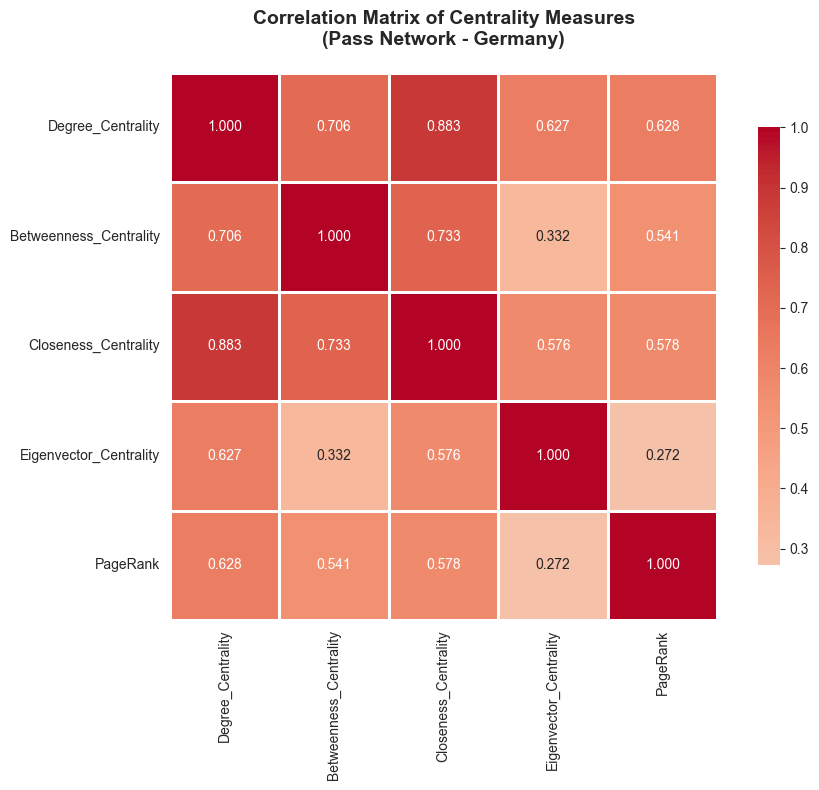

Figure saved: reports/figures/LE5/centrality_correlation.png


In [16]:
### 4.4 Visualization - Centrality Correlation Heatmap

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, 
            cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title('Correlation Matrix of Centrality Measures\n(Pass Network - Germany)', 
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'centrality_correlation.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/centrality_correlation.png")

## 5. Group-Level Analysis: k-Core and k-Shell

**k-Core**: A maximal subgraph where every node has degree at least $k$ within that subgraph.

**k-Shell**: Nodes that belong to the $k$-core but not to the $(k+1)$-core.

**Core Number**: The highest $k$ for which a node belongs to a $k$-core.

### Interpretation
- **High core number** → node is in a densely connected group
- k-cores reveal hierarchical structure of connectivity
- Core decomposition is useful for finding cohesive subgroups
- In pass networks: identifies groups of players with dense passing connections

In [17]:
### 5.1 k-Core Decomposition

# Compute core numbers
core_numbers = nx.core_number(G_pass_cc)

df_cores = pd.DataFrame({
    'Player': list(core_numbers.keys()),
    'Core_Number': list(core_numbers.values()),
})
df_cores = df_cores.sort_values('Core_Number', ascending=False)

print("=== Core Number Statistics ===")
print(f"Max core number (k-max): {df_cores['Core_Number'].max()}")
print(f"Mean core number: {df_cores['Core_Number'].mean():.2f}")
print(f"Median core number: {df_cores['Core_Number'].median():.0f}")

# Distribution of core numbers
core_dist = df_cores['Core_Number'].value_counts().sort_index(ascending=False)
print("\n=== Core Number Distribution ===")
for k, count in core_dist.head(10).items():
    print(f"k={k}: {count} players")

# Players in highest core
max_core = df_cores['Core_Number'].max()
highest_core_players = df_cores[df_cores['Core_Number'] == max_core]
print(f"\n=== Players in Highest Core (k={max_core}) ===")
print(f"Number of players: {len(highest_core_players)}")
print("\nPlayers:")
print(highest_core_players['Player'].to_string(index=False))

=== Core Number Statistics ===
Max core number (k-max): 20
Mean core number: 16.25
Median core number: 18

=== Core Number Distribution ===
k=20: 24 players
k=19: 84 players
k=18: 129 players
k=17: 83 players
k=16: 66 players
k=15: 11 players
k=14: 4 players
k=13: 8 players
k=12: 3 players
k=11: 12 players

=== Players in Highest Core (k=20) ===
Number of players: 24

Players:
284524
 16094
 20680
 18669
263490
 91519
 15543
279734
 14707
 15278
275384
 15317
127685
 15039
 94831
356903
356928
272338
 16843
 14863
 15194
 15122
 15253
 15265


In [18]:
### 5.2 Core Numbers vs Other Centrality Measures

# Merge core numbers with centrality data
df_with_cores = df_all_centrality.merge(df_cores, on='Player', how='left')
df_with_cores['Core_Number'] = df_with_cores['Core_Number'].fillna(0)

# Correlations
print("=== Correlation: Core Number vs Centrality Measures ===\n")
for measure in ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
                'Eigenvector_Centrality', 'PageRank']:
    corr = df_with_cores['Core_Number'].corr(df_with_cores[measure])
    print(f"{measure:30s}: {corr:.3f}")

# Top players by core number and degree
print("\n=== Top 20 Players by Core Number (with Degree) ===\n")
df_display = df_with_cores.sort_values('Core_Number', ascending=False)
print(df_display[['Player', 'Core_Number', 'Degree', 'Degree_Centrality', 'Betweenness_Centrality']].head(20).to_string(index=False))

=== Correlation: Core Number vs Centrality Measures ===

Degree_Centrality             : 0.832
Betweenness_Centrality        : 0.359
Closeness_Centrality          : 0.790
Eigenvector_Centrality        : 0.561
PageRank                      : 0.474

=== Top 20 Players by Core Number (with Degree) ===

Player  Core_Number  Degree  Degree_Centrality  Betweenness_Centrality
 16094           20      45           0.095339                0.011540
127685           20      31           0.065678                0.013363
263490           20      25           0.052966                0.000363
 94831           20      31           0.065678                0.007105
279734           20      21           0.044492                0.000658
 20680           20      28           0.059322                0.005321
 15194           20      22           0.046610                0.000615
 15317           20      29           0.061441                0.005974
 18669           20      27           0.057203              

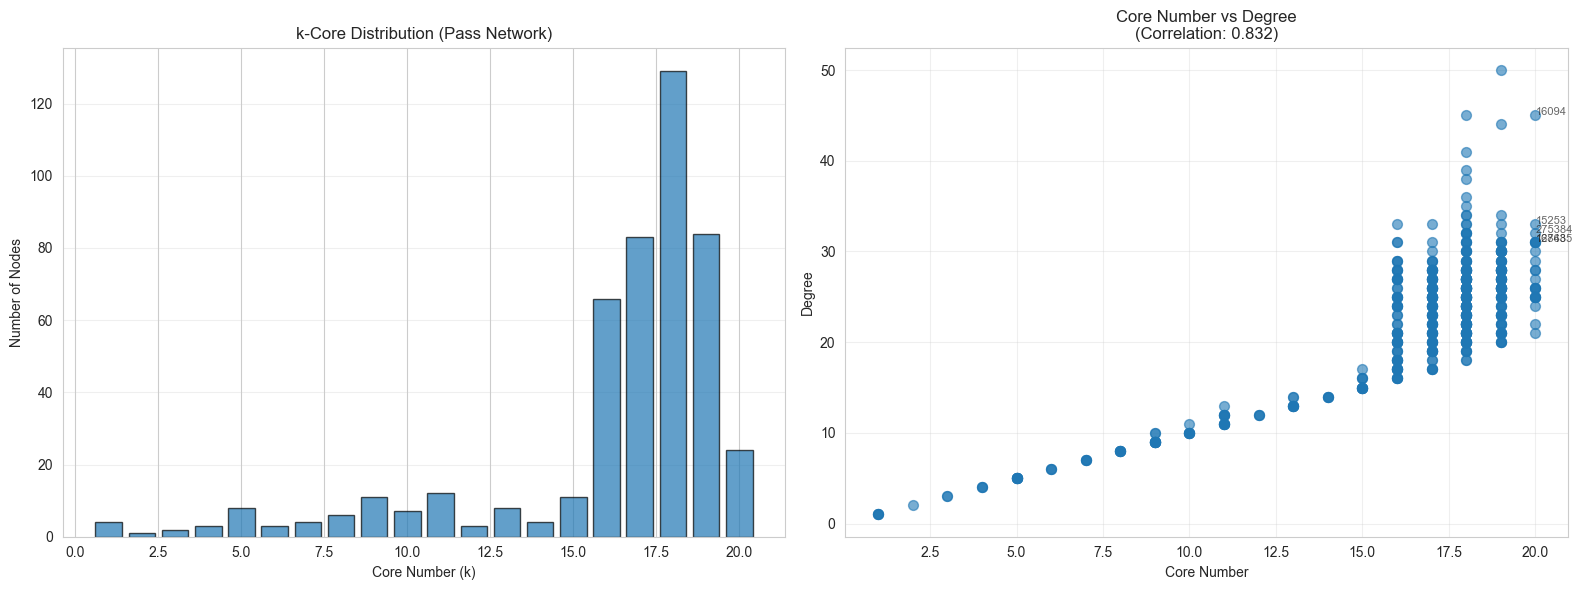

Figure saved: reports/figures/LE5/kcore_analysis.png


In [19]:
### 5.3 Visualization - Core Number Distribution and Scatter

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Core number distribution
axes[0].bar(core_dist.index, core_dist.values, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Core Number (k)')
axes[0].set_ylabel('Number of Nodes')
axes[0].set_title('k-Core Distribution (Pass Network)')
axes[0].grid(True, alpha=0.3, axis='y')

# Core number vs Degree scatter
axes[1].scatter(df_with_cores['Core_Number'], df_with_cores['Degree'], alpha=0.6, s=50)
axes[1].set_xlabel('Core Number')
axes[1].set_ylabel('Degree')
axes[1].set_title(f'Core Number vs Degree\n(Correlation: {df_with_cores["Core_Number"].corr(df_with_cores["Degree"]):.3f})')
axes[1].grid(True, alpha=0.3)

# Annotate some high-core players
top_core = df_with_cores.nlargest(5, 'Core_Number')
for _, row in top_core.iterrows():
    if pd.notna(row['Player']) and pd.notna(row['Core_Number']) and pd.notna(row['Degree']):
        axes[1].annotate(row['Player'][:15], 
                        (row['Core_Number'], row['Degree']),
                        fontsize=8, alpha=0.7)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'kcore_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/kcore_analysis.png")

## 6. Centrality Analysis on Match Network (Teams)

Now we apply the same centrality measures to the **match network** (World Cup), where nodes are teams and edges represent matches.

In [20]:
### 6.1 Match Network - All Centrality Measures

# Get largest component
components_match = list(nx.connected_components(G_match))
largest_cc_match = max(components_match, key=len)
G_match_cc = G_match.subgraph(largest_cc_match).copy()

print(f"Match Network - Largest CC: {len(largest_cc_match)} / {G_match.number_of_nodes()} teams\n")

# Calculate all centrality measures
degree_cent_match = nx.degree_centrality(G_match_cc)
betweenness_cent_match = nx.betweenness_centrality(G_match_cc)
closeness_cent_match = nx.closeness_centrality(G_match_cc)

try:
    eigenvector_cent_match = nx.eigenvector_centrality(G_match_cc, max_iter=500)
except (nx.PowerIterationFailedConvergence, nx.NetworkXError):
    eigenvector_cent_match = nx.eigenvector_centrality_numpy(G_match_cc)

# For directed network
components_match_dir = list(nx.weakly_connected_components(G_match_dir))
largest_cc_match_dir = max(components_match_dir, key=len)
G_match_dir_cc = G_match_dir.subgraph(largest_cc_match_dir).copy()
pagerank_match = nx.pagerank(G_match_dir_cc, alpha=0.85)

# Create dataframe
df_match_centrality = pd.DataFrame({
    'Team': list(degree_cent_match.keys()),
    'Degree_Centrality': [degree_cent_match[t] for t in degree_cent_match.keys()],
    'Betweenness_Centrality': [betweenness_cent_match[t] for t in degree_cent_match.keys()],
    'Closeness_Centrality': [closeness_cent_match[t] for t in degree_cent_match.keys()],
    'Eigenvector_Centrality': [eigenvector_cent_match[t] for t in degree_cent_match.keys()],
})

# Add PageRank
df_pagerank_match = pd.DataFrame({
    'Team': list(pagerank_match.keys()),
    'PageRank': list(pagerank_match.values())
})
df_match_centrality = df_match_centrality.merge(df_pagerank_match, on='Team', how='left')

# Calculate average rank
for col in ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
            'Eigenvector_Centrality', 'PageRank']:
    df_match_centrality[f'{col}_rank'] = df_match_centrality[col].rank(ascending=False)

rank_cols_match = [c for c in df_match_centrality.columns if c.endswith('_rank')]
df_match_centrality['Avg_Rank'] = df_match_centrality[rank_cols_match].mean(axis=1)
df_match_centrality = df_match_centrality.sort_values('Avg_Rank')

print("=== Top 15 Teams by Average Centrality Rank (World Cup) ===\n")
display_cols_match = ['Team', 'Degree_Centrality', 'Betweenness_Centrality', 
                      'Closeness_Centrality', 'Eigenvector_Centrality', 'PageRank', 'Avg_Rank']
print(df_match_centrality[display_cols_match].head(15).to_string(index=False))

Match Network - Largest CC: 32 / 32 teams

=== Top 15 Teams by Average Centrality Rank (World Cup) ===

 Team  Degree_Centrality  Betweenness_Centrality  Closeness_Centrality  Eigenvector_Centrality  PageRank  Avg_Rank
 4418           0.225806                0.325842              0.442857                0.392332  0.036391       3.4
 9598           0.225806                0.325842              0.442857                0.392332  0.035941       3.6
 2413           0.193548                0.324767              0.442857                0.269910  0.034243       5.4
14358           0.161290                0.174229              0.360465                0.205881  0.042112       5.8
 5629           0.193548                0.324767              0.442857                0.269910  0.028679       6.4
 7047           0.161290                0.164516              0.356322                0.121991  0.041349       8.6
12274           0.129032                0.013620              0.352273                0.258

=== Correlation Matrix - Match Network ===

                        Degree_Centrality  Betweenness_Centrality  \
Degree_Centrality                   1.000                   0.963   
Betweenness_Centrality              0.963                   1.000   
Closeness_Centrality                0.857                   0.862   
Eigenvector_Centrality              0.744                   0.711   
PageRank                            0.085                   0.039   

                        Closeness_Centrality  Eigenvector_Centrality  PageRank  
Degree_Centrality                      0.857                   0.744     0.085  
Betweenness_Centrality                 0.862                   0.711     0.039  
Closeness_Centrality                   1.000                   0.894     0.030  
Eigenvector_Centrality                 0.894                   1.000    -0.036  
PageRank                               0.030                  -0.036     1.000  


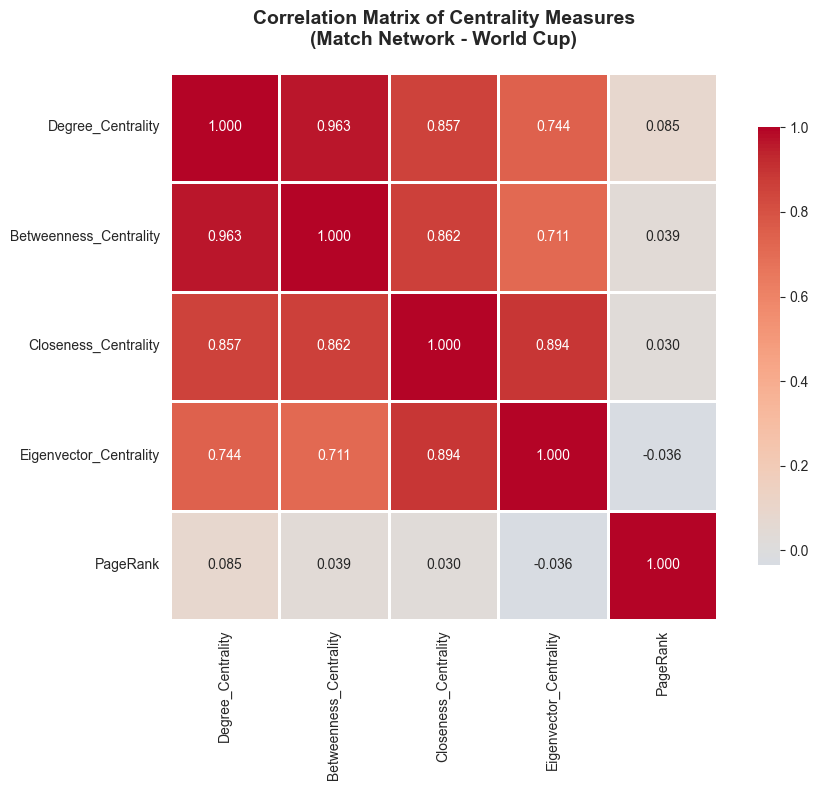


Figure saved: reports/figures/LE5/centrality_correlation_match.png


In [21]:
### 6.2 Match Network - Correlation Analysis

# Correlation matrix for match network
centrality_cols_match = ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
                         'Eigenvector_Centrality', 'PageRank']
corr_matrix_match = df_match_centrality[centrality_cols_match].corr()

print("=== Correlation Matrix - Match Network ===\n")
print(corr_matrix_match.round(3))

# Visualization
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(corr_matrix_match, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, 
            cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title('Correlation Matrix of Centrality Measures\n(Match Network - World Cup)', 
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'centrality_correlation_match.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("\nFigure saved: reports/figures/LE5/centrality_correlation_match.png")

## 7. Summary and Key Findings

Let's summarize the most central actors identified across all measures.

In [22]:
### 7.1 Top Central Players Summary

print("="*80)
print("SUMMARY: TOP CENTRAL ACTORS")
print("="*80)

print("\n### PASS NETWORK (Germany) - Top 5 by Each Measure ###\n")

print("Degree Centrality (Most Connected):")
for i, row in df_degree_pass.head(5).iterrows():
    print(f"  {row['Player']:40s} - Degree: {row['Degree']:.0f}")

print("\nBetweenness Centrality (Best Bridges):")
for i, row in df_betweenness.head(5).iterrows():
    print(f"  {row['Player']:40s} - Betweenness: {row['Betweenness_Centrality']:.6f}")

print("\nCloseness Centrality (Most Accessible):")
for i, row in df_closeness.head(5).iterrows():
    print(f"  {row['Player']:40s} - Closeness: {row['Closeness_Centrality']:.6f}")

print("\nPageRank (Most Influential):")
for i, row in df_pagerank.head(5).iterrows():
    print(f"  {row['Player']:40s} - PageRank: {row['PageRank']:.6f}")

print("\nCore Number (Most Dense Connections):")
for i, row in df_cores.head(5).iterrows():
    print(f"  {row['Player']:40s} - Core: {row['Core_Number']:.0f}")

print("\n" + "="*80)
print("\n### MATCH NETWORK (World Cup) - Top 5 Overall ###\n")

for i, row in df_match_centrality.head(5).iterrows():
    print(f"{row['Team']:30s} - Avg Rank: {row['Avg_Rank']:.2f}")

SUMMARY: TOP CENTRAL ACTORS

### PASS NETWORK (Germany) - Top 5 by Each Measure ###

Degree Centrality (Most Connected):
  15085                                    - Degree: 50
  16094                                    - Degree: 45
  284469                                   - Degree: 45
  149389                                   - Degree: 44
  14731                                    - Degree: 41

Betweenness Centrality (Best Bridges):
  336829                                   - Betweenness: 0.026213
  302600                                   - Betweenness: 0.026010
  65075                                    - Betweenness: 0.023694
  14795                                    - Betweenness: 0.020566
  14749                                    - Betweenness: 0.018584

Closeness Centrality (Most Accessible):
  65075                                    - Closeness: 0.433425
  14795                                    - Closeness: 0.428312
  302600                                   - Closenes

In [ ]:
### 7.2 Export Results for LaTeX

# Save pass network centrality results
df_with_cores.to_csv(project_root / 'reports' / 'figures' / 'LE5' / 'player_centrality.csv', index=False)
print("Saved: reports/figures/LE5/player_centrality.csv")

# Save match network centrality results
df_match_centrality.to_csv(project_root / 'reports' / 'figures' / 'LE5' / 'team_centrality.csv', index=False)
print("Saved: reports/figures/LE5/team_centrality.csv")

# Create LaTeX table for top players
top_10_overall = df_with_cores.nsmallest(10, 'Avg_Rank')
latex_table = top_10_overall[['Player', 'Degree', 'Betweenness_Centrality', 'Closeness_Centrality', 
                               'PageRank', 'Core_Number']].copy()

# Round values
latex_table['Betweenness_Centrality'] = latex_table['Betweenness_Centrality'].round(4)
latex_table['Closeness_Centrality'] = latex_table['Closeness_Centrality'].round(4)
latex_table['PageRank'] = latex_table['PageRank'].round(4)

with open(project_root / 'reports' / 'figures' / 'LE5' / 'top_players_table.tex', 'w') as f:
    f.write(latex_table.to_latex(index=False, escape=False))

print("Saved: reports/figures/LE5/top_players_table.tex")

Saved: reports/figures/LE5/player_centrality.csv
Saved: reports/figures/LE5/team_centrality.csv
Saved: reports/figures/LE5/top_players_table.tex

Analysis complete! All results saved to reports/figures/LE5/
